# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
-negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

In [12]:
def confusion_matrix(y_true, y_pred):
    tp = np.sum(y_true[np.where(y_pred)])
    fn = np.sum(y_true[np.where(1-y_pred)])
    fp = np.sum((1-y_true)[np.where(y_pred)])
    tn = np.sum((1-y_true)[np.where(1-y_pred)])

    return tp,fn, fp,tn

def classification_report(y_true, y_pred):
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)

    # accuracy, precision, recall and F1 from the four counts
    precision = tp / (tp+fp)
    accuracy = (tp+tn) / (tp+ fn+ fp+tn)
    recall = tp / (tp+fn)
    F1 = (tp+tp)/(tp+tp+fp+fn)

    return accuracy, precision, recall, F1

def roc_curve(y_true, scores):
    thresholds = np.linspace(0,1, 1000)
    TPR = np.empty_like(thresholds)
    FPR = np.empty_like(thresholds)
    for i, t in enumerate(thresholds):
        y_pred = np.zeros_like(y_true)
        y_pred[np.where(scores > t)] = 1

        tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
        TPR[i] = tp/(tp+fn)
        FPR[i] = tn/(tn+fp)

    sorted_index = FPR.argsort()
    FPR = FPR[sorted_index]
    TPR = TPR[sorted_index]

    return FPR, TPR

def auc_trapezoid(fpr, tpr):
    area = np.sum(((tpr[:-1]+tpr[1:])/2)*(fpr[1:]-fpr[:-1]))
    return area

def roc_auc(y_true, scores):
    pos = scores[np.where(y_true==1)].sort()
    npos = np.sum(y_true)
    nneg = len(y_true) - npos
    AUC = 0
    for score in scores:
        R_i = len(np.where(scores > score))
        AUC += R_i - (1/2)*(npos*(npos + 1))
    AUC /= npos*nneg
    return AUC

# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(np.int64(5), np.int64(1), np.int64(1), np.int64(13)) [[13  1]
 [ 1  5]]
-4.761904761904762 0.8571428571428572 0.8571428571428571


We were unable to implement the rank formula, as the formula from the lectures do not sufficiently describe the notation.

**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


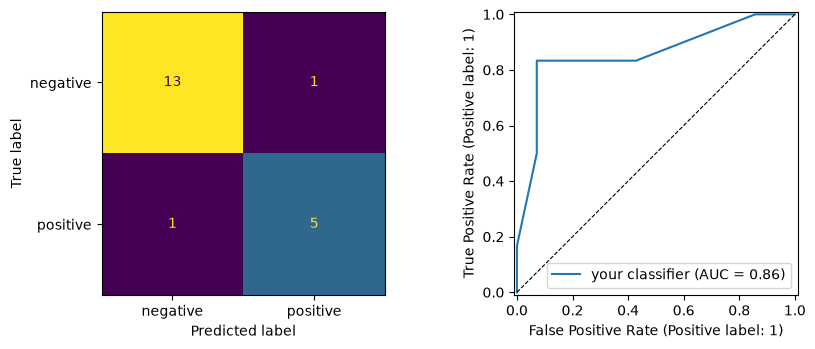

In [13]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test_logreg = y_small, s_small          # replace by your test labels and output probabilities
y_pred_logreg = p_test_logreg > 0.5

cm = sk_confusion_matrix(y_test, y_pred_logreg)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred_logreg):.4f}  precision {precision_score(y_test, y_pred_logreg, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred_logreg):.4f}  F1 {f1_score(y_test, y_pred_logreg):.4f}")
print(sk_classification_report(y_test, y_pred_logreg, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test_logreg, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test_logreg):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test_logreg, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.

Our confusion matrix:
[[ 686 8179]
 [   1 1134]]
Our classification report: accuracy 0.1820  precision 0.1218  recall 0.9991  F1 0.2171
[[ 686 8179]
 [   1 1134]]
accuracy 0.1820  precision 0.1218  recall 0.9991  F1 0.2171
              precision    recall  f1-score   support

    negative       1.00      0.08      0.14      8865
    positive       0.12      1.00      0.22      1135

    accuracy                           0.18     10000
   macro avg       0.56      0.54      0.18     10000
weighted avg       0.90      0.18      0.15     10000

AUC 0.5220


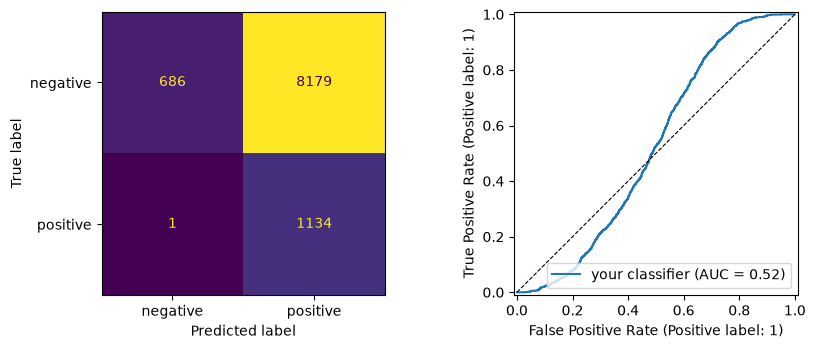

Our confusion matrix:
[[7495 1370]
 [ 443  692]]
Our classification report: accuracy 0.8187  precision 0.3356  recall 0.6097  F1 0.4329
[[7495 1370]
 [ 443  692]]
accuracy 0.8187  precision 0.3356  recall 0.6097  F1 0.4329
              precision    recall  f1-score   support

    negative       0.94      0.85      0.89      8865
    positive       0.34      0.61      0.43      1135

    accuracy                           0.82     10000
   macro avg       0.64      0.73      0.66     10000
weighted avg       0.88      0.82      0.84     10000

AUC 0.8207


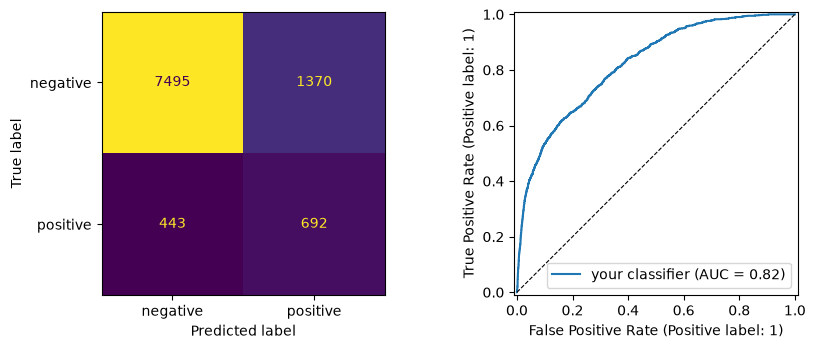

In [173]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)
np.set_printoptions(suppress=True)

def create_layers_batched(network_input_size, layer_output_sizes):
    layers = []

    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = np.random.randn(i_size, layer_output_size)
        b = np.random.randn(layer_output_size)
        layers.append((W, b))

        i_size = layer_output_size
    return layers

def feed_forward_saver_batched(input, layers, activation_funcs):
    layer_inputs = []
    zs = []
    a = input
    for (W, b), activation_func in zip(layers, activation_funcs):
        layer_inputs.append(a)
        z = a @ W + b
        a = activation_func(z)

        zs.append(z)

    return layer_inputs, zs, a

def mse(predict, target):
    return np.mean((predict - target) ** 2)

def mse_der(predict, target):
    return (2/predict.size)*(predict.ravel()-target.ravel())

def backpropagation_batched(
        input, layers, activation_funcs, target, activation_ders, cost_der=mse_der
    ):
    layer_inputs, zs, predict = feed_forward_saver_batched(input, layers, activation_funcs)

    layer_grads = [() for layer in layers]

    # We loop over the layers, from the last to the first
    for i in reversed(range(len(layers))):
        layer_input, z, activation_der = layer_inputs[i], zs[i], activation_ders[i]

        if i == len(layers) - 1:
            # For last layer we use cost derivative as dC_da(L) can be computed directly
            if activation_der == None:
                dC_dz = predict - target
            else:
                dC_da = cost_der(predict, target)
                dC_dz = (dC_da * activation_der(z).T).T
        else:
            # For other layers we build on previous z derivative, as dC_da(i) = dC_dz(i+1) * dz(i+1)_da(i)
            (W, b) = layers[i + 1]
            dC_da = dC_dz @ W.T
            dC_dz = dC_da * activation_der(z)

        dC_dW = layer_input.T @ dC_dz
        dC_db = np.sum(dC_dz, axis=0)

        layer_grads[i] = (dC_dW, dC_db)
    return layer_grads

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, a_min=-100, a_max=100)))

def sigmoid_der(z):
    der = np.exp(-np.clip(z, a_min=-100, a_max=100))/(1+np.exp(-np.clip(z, a_min=-100, a_max=100)))**2
    return der

d = 1                                   # your digit
data = np.load("mnist.npz")             # see Project 2 for where to get it
x_train = data["x_train"].reshape(len(data["x_train"]), -1) / 255.0
x_test = data["x_test"].reshape(len(data["x_test"]), -1) / 255.0
y_train = (data["y_train"] == d).astype(float)
y_test = (data["y_test"] == d).astype(float)

def split_minibatches(inputs, targets, M=5, rng = np.random.default_rng(2026)):
    n = len(targets)
    # Resample data in case n is not divisible by M
    if n%M:
        num_resample = M - n%M
        resample_idx = rng.permutation(n)
        inputs = np.append(inputs, inputs[resample_idx[:num_resample]])
        targets = np.append(targets, targets[resample_idx[:num_resample]])
    else:
        num_resample = 0

    shuffled_idx = rng.permutation(n+num_resample)
    inputs_shuffled = inputs[shuffled_idx]
    targets_shuffled = targets[shuffled_idx]
    input_batches = np.split(inputs_shuffled, n//M)
    target_batches = np.split(targets_shuffled, n//M)

    batches = []
    for input_mini, target_mini in zip(input_batches, target_batches):
        batches.append((input_mini, target_mini))

    return batches

def train_stochastic(
        inputs, layers, activation_funcs, targets,
        activation_ders, M=5, gamma=0.001, epochs=1000,
        rng = np.random.default_rng(2026)
    ):
    n, _ = inputs.shape
    for _ in range(epochs):
        print(f"\rEpoch: {_+1}/{epochs}", end="")
        minibatches = split_minibatches(inputs, targets, M, rng)
        for (inputs_mini, targets_mini) in minibatches:
            layers_grad = backpropagation_batched(
                inputs_mini,
                layers,
                activation_funcs,
                targets_mini,
                activation_ders
            )

            layers = [
                (W - gamma*M/n * dW, b - gamma*M/n * db)
                for (W, b), (dW, db) in zip(layers, layers_grad)
            ]

    print("\r", end="")
    return layers

input_size = 28*28
layer_output_sizes = [1]
activation_funcs = [sigmoid]
activation_ders = [sigmoid_der]
layers_untrained = create_layers_batched(input_size, layer_output_sizes)

layers_logreg = train_stochastic(x_train, layers_untrained, activation_funcs, y_train, activation_ders, M=6000, epochs=100)
_, _, predict_logreg = feed_forward_saver_batched(x_test, layers_logreg, activation_funcs)
y_pred_logreg = np.zeros_like(predict_logreg)
y_pred_logreg[np.where(predict_logreg > 0.5)] = 1

p_test_logreg = predict_logreg.ravel()
y_pred_logreg = y_pred_logreg.ravel()

tp, fn, fp, tn = confusion_matrix(y_test, y_pred_logreg)
M = np.array([
    [int(tn), int(fp)],
    [int(fn), int(tp)]
])
print("Our confusion matrix:")
print(M)

accuracy, precision, recall, f1 = classification_report(y_test, y_pred_logreg)

print("Our classification report: ", end="")
print(f"accuracy {accuracy:.4f}  precision {precision:.4f}  "
      f"recall {recall:.4f}  F1 {f1:.4f}")

accuracy_se_logreg = np.sqrt(accuracy*(1-accuracy)/len(y_test))
recall_se_logreg = np.sqrt(recall*(1-recall)/len(y_test))

cm = sk_confusion_matrix(y_test, y_pred_logreg)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred_logreg):.4f}  precision {precision_score(y_test, y_pred_logreg, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred_logreg):.4f}  F1 {f1_score(y_test, y_pred_logreg):.4f}")
print(sk_classification_report(y_test, y_pred_logreg, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test_logreg, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test_logreg):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test_logreg, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
FPR_05_logreg = fp/(fp + tn)
TPR_05_logreg = tp/(tp + fn)
plt.tight_layout(); plt.show()

input_size = 28*28
layer_output_sizes = [50, 1]
activation_funcs = [sigmoid, sigmoid]
activation_ders = [sigmoid_der, sigmoid_der]
layers_untrained = create_layers_batched(input_size, layer_output_sizes)

layers_nn = train_stochastic(x_train, layers_untrained, activation_funcs, y_train, activation_ders, M=6000, epochs=100)
_, _, predict_nn = feed_forward_saver_batched(x_test, layers_nn, activation_funcs)
y_pred_nn = np.zeros_like(predict_nn)
y_pred_nn[np.where(predict_nn > 0.5)] = 1

p_test_nn = predict_nn.ravel()
y_pred_nn = y_pred_nn.ravel()

tp, fn, fp, tn = confusion_matrix(y_test, y_pred_nn)
M = np.array([
    [int(tn), int(fp)],
    [int(fn), int(tp)]
])
print("Our confusion matrix:")
print(M)

accuracy, precision, recall, f1 = classification_report(y_test, y_pred_nn)

print("Our classification report: ", end="")
print(f"accuracy {accuracy:.4f}  precision {precision:.4f}  "
      f"recall {recall:.4f}  F1 {f1:.4f}")

accuracy_se_nn = np.sqrt(accuracy*(1-accuracy)/len(y_test))
recall_se_nn = np.sqrt(recall*(1-recall)/len(y_test))

cm = sk_confusion_matrix(y_test, y_pred_nn)   # [[TN, FP], [FN, TP]]
print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred_nn):.4f}  precision {precision_score(y_test, y_pred_nn, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred_nn):.4f}  F1 {f1_score(y_test, y_pred_nn):.4f}")
print(sk_classification_report(y_test, y_pred_nn, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test_nn, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test_nn):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, p_test_nn, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
FPR_05_nn = fp/(fp + tn)
TPR_05_nn = tp/(tp + fn)
plt.tight_layout(); plt.show()

The matrices tell us where we are inaccurate. In this problem, because we have imbalanced data, randomly guessing would give about 50% accuracy, however choosing all negatives would give us 90% accuracy. By looking at the matrices, we can tell what proportion of actual positives are predicted as positives, and the same with negatives, giving us an idea how much the model can actually distinguish the classes.

In this situation, we didn't actually get over 90% accuracy, probably because the models didn't converge. But for $0 < e < 1$, if the majority rule accuracy is $A$ and the accuracy obtained by the classifier is $A + (1-A)e$, then $e$ would be the fraction of the remaining error that the classifier removed.



**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?

Logistic regression:
AUC trapezoid: 0.5939387931055902
AUC sklearn: 0.521972713561971
Logistic regression:
AUC trapezoid: 0.8206841238250706
AUC sklearn: 0.8206851176854979


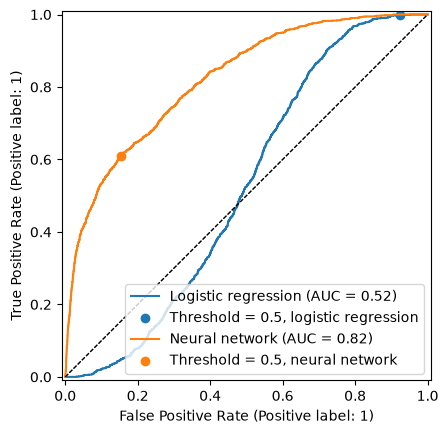

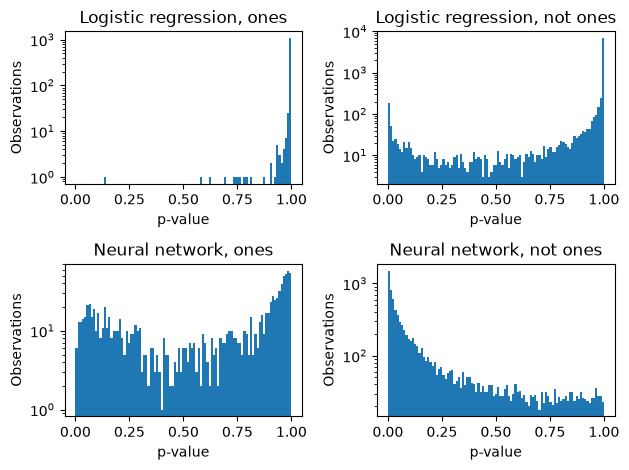

In [175]:
fig, ax = plt.subplots()
RocCurveDisplay.from_predictions(y_test, p_test_logreg.copy(), ax=ax, name="Logistic regression")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.scatter(FPR_05_logreg, TPR_05_logreg, label="Threshold = 0.5, logistic regression")

FPR, TPR = roc_curve(y_test, p_test_logreg)
AUC_trap = auc_trapezoid(FPR, TPR)
AUC_sklearn = roc_auc_score(y_test, p_test_logreg)

print("Logistic regression:")
print(f"AUC trapezoid: {AUC_trap}")
print(f"AUC sklearn: {AUC_sklearn}")

RocCurveDisplay.from_predictions(y_test, p_test_nn.copy(), ax=ax, name="Neural network")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.scatter(FPR_05_nn, TPR_05_nn, label=f"Threshold = 0.5, neural network")

FPR, TPR = roc_curve(y_test, p_test_nn)
AUC_trap = auc_trapezoid(FPR, TPR)
AUC_sklearn = roc_auc_score(y_test, p_test_nn)

print("Logistic regression:")
print(f"AUC trapezoid: {AUC_trap}")
print(f"AUC sklearn: {AUC_sklearn}")

plt.legend()
plt.show()

ones_idx = np.where(y_test == 1)
not_ones_idx = np.where(y_test != 1)

p_test_logreg_ones = p_test_logreg[ones_idx]
p_test_logreg_not_ones = p_test_logreg[not_ones_idx]

p_test_nn_ones = p_test_nn[ones_idx]
p_test_nn_not_ones = p_test_nn[not_ones_idx]

bins = np.linspace(0, 1, 100)

fig, ax = plt.subplots(2, 2)

ax[0][0].hist(p_test_logreg_ones, bins=bins)
ax[0][0].set_yscale("log")
ax[0][0].set_title("Logistic regression, ones")
ax[0][0].set_xlabel("p-value")
ax[0][0].set_ylabel("Observations")

ax[0][1].hist(p_test_logreg_not_ones, bins=bins)
ax[0][1].set_yscale("log")
ax[0][1].set_title("Logistic regression, not ones")
ax[0][1].set_xlabel("p-value")
ax[0][1].set_ylabel("Observations")

ax[1][0].hist(p_test_nn_ones, bins=bins)
ax[1][0].set_yscale("log")
ax[1][0].set_title("Neural network, ones")
ax[1][0].set_xlabel("p-value")
ax[1][0].set_ylabel("Observations")

ax[1][1].hist(p_test_nn_not_ones, bins=bins)
ax[1][1].set_yscale("log")
ax[1][1].set_title("Neural network, not ones")
ax[1][1].set_xlabel("p-value")
ax[1][1].set_ylabel("Observations")

plt.tight_layout()
plt.show()

The error of the logistic regression model is definitely more located in the class of not ones, as the p-values seem to be more clustered toward 1. For the neural network model, the error is located in the class of ones, as the p-values of the class of ones is more spread. So for the logistic regression model, it seems like it is biased toward classifying samples as ones, and the neural network is biased toward classifying samples as zeros.

With a high AUC, the model is less likely to give high p-values to negatives and low p-values to positives. The AUC can also tell us how certain the model is, as a high AUC will have fewer p-values toward the center, i.e. away from 0 and 1.

**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

In [177]:
print("Standard error:")
print(f"Logistic regression:    accuracy {accuracy_se_logreg:.4f}   recall {recall_se_logreg:.4f}")
print(f"Neural network:         accuracy {accuracy_se_nn:.4f}   recall {recall_se_nn:.4f}")

Standard error:
Logistic regression:    accuracy 0.0039   recall 0.0003
Neural network:         accuracy 0.0039   recall 0.0049


With accuracies of ${\sim} 0.8$ and ${\sim} 0.2$, the difference is definitely significant, as the difference is orders of magnitude larger than the estimated standard error of $0.0039$. The logistic regression model is terrible (probably needed more epochs of training) and there is probably a threshold (likely ${\sim} 0.9$) for the neural network that gives a better accuracy than classifying everything as negative.

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
...

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …